In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/abdulwadood11220/netflix-customer-churn-dataset/netflix_customer_churn.csv


In [2]:
df = pd.read_csv("/kaggle/input/datasets/abdulwadood11220/netflix-customer-churn-dataset/netflix_customer_churn.csv")
df

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi


In [3]:
df["subscription_type"] = df["subscription_type"].map({"Basic":1, "Premium":2, "Standard":3})
df

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,1,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,3,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,3,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,2,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,3,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,1,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,1,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,3,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,1,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi


In [4]:
df["device"] = df["device"].map({"Mobile":1, "Tablet":2, "Laptop":3,"Desktop":4, "TV": 5})
np.unique(df["device"])

array([1, 2, 3, 4, 5])

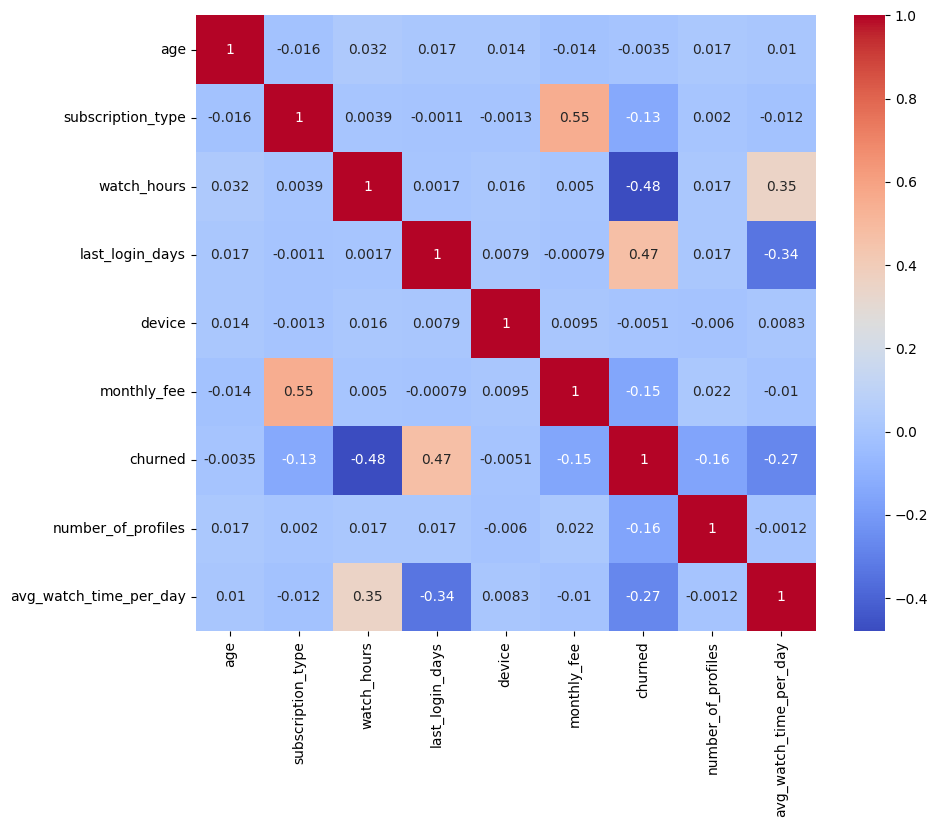

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [7]:
x,y = df[["age", "subscription_type", "watch_hours", "monthly_fee"]], df["churned"]
x,y

(      age  subscription_type  watch_hours  monthly_fee
 0      51                  1        14.73         8.99
 1      47                  3         0.70        13.99
 2      27                  3        16.32        13.99
 3      53                  2         4.51        17.99
 4      56                  3         1.89        13.99
 ...   ...                ...          ...          ...
 4995   19                  1        49.17         8.99
 4996   67                  1         9.24         8.99
 4997   66                  3        16.55        13.99
 4998   59                  1         9.12         8.99
 4999   57                  1         1.62         8.99
 
 [5000 rows x 4 columns],
 0       1
 1       1
 2       0
 3       1
 4       1
        ..
 4995    0
 4996    0
 4997    1
 4998    0
 4999    1
 Name: churned, Length: 5000, dtype: int64)

In [8]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y,test_size=0.2, random_state= 42, stratify=y)

In [9]:
def gini(y):
    cls, cnt = np.unique(y, return_counts=True)
    impr =1
    for count in cnt:
        impr-= (count/len(y))**2
    return impr

In [10]:
def split(x,y,feature, thrashhold):
    left = x[feature]<=thrashhold
    right = x[feature]>thrashhold

    return (x[left],y[left], x[right], y[right])

In [11]:
split(xtrain,ytrain, "age",30)

(      age  subscription_type  watch_hours  monthly_fee
 1310   23                  2         4.03        17.99
 2139   20                  3         2.89        13.99
 3293   18                  1         7.65         8.99
 134    19                  1         5.18         8.99
 2619   19                  3         1.68        13.99
 ...   ...                ...          ...          ...
 3467   28                  2        28.72        17.99
 2244   30                  3         3.36        13.99
 1360   30                  2         1.85        17.99
 202    23                  1        18.25         8.99
 1411   29                  3         1.56        13.99
 
 [1039 rows x 4 columns],
 1310    0
 2139    1
 3293    1
 134     1
 2619    0
        ..
 3467    0
 2244    0
 1360    0
 202     0
 1411    1
 Name: churned, Length: 1039, dtype: int64,
       age  subscription_type  watch_hours  monthly_fee
 1465   31                  1         4.83         8.99
 3556   64             

In [12]:
def split_score(ly,ry):
    n = len(ly)+len(ry)
    return (len(ly)/n)*gini(ly) + (len(ry)/n)*gini(ry)

In [13]:
def best_split(x,y):
    best = None
    bestscr = float("inf")

    for feature in x:
        values = np.unique(x[feature])

        for trashold in values:
            xl, yl, xr, yr = split(x,y,feature, trashold)
            if len(yl) == 0 or len(yr)==0:
                continue
            score = split_score(yl,yr)

            if score<bestscr:
                bestscr = score
                best = {
                    "feature": feature,
                    "trashold": trashold,
                    "left": (xl,yl),
                    "right": (xr,yr)
                }
    return best

In [14]:
class Node:
    def __init__(self, feature=None, trashold=None, left=None, right=None, value=None):
        self.feature = feature
        self.trashold = trashold
        self.left = left
        self.right = right
        self.value = value

In [15]:
def build_tree(X,Y,depth, max_depth):
    if depth == max_depth or len(set(Y)) == 1:
        # print(depth,"v", max(set(Y), key=list(Y).count), gini(Y), np.unique(Y, return_counts=True))
        return Node(value=max(set(Y), key=list(Y).count))
    best = best_split(X,Y)
    left = build_tree(best["left"][0], best["left"][1], depth+1, max_depth)
    right = build_tree(best["right"][0], best["right"][1], depth+1, max_depth)
    # print(depth,"f", best["feature"], best["trashold"], split_score(best["left"][1],best["right"][1]), np.unique(left, return_counts=True), np.unique(right, return_counts=True))
    return Node(feature=best["feature"], trashold=best["trashold"], left=left, right=right)

In [16]:
def run_tree(node,x):
    if node.value is not None:
        return node.value
    if x[node.feature]<=node.trashold:
        return run_tree(node.left,x)
    else:
        return run_tree(node.right, x)

In [17]:
for i in range(1,10):
    tree = build_tree(xtrain,ytrain,0,i)
    prediction = xtest.apply(lambda x:run_tree(tree, x), axis=1)
    predictiontrain = xtrain.apply(lambda x:run_tree(tree, x), axis=1)
    print(i,accuracy_score(prediction,ytest), accuracy_score(predictiontrain,ytrain))

1 0.743 0.73625
2 0.743 0.73625
3 0.769 0.75025
4 0.769 0.76025
5 0.762 0.764
6 0.751 0.769
7 0.752 0.77425
8 0.729 0.7815
9 0.742 0.79375
